# AI-Based Multi-Label Vehicle Damage Detection Using Deep Learning
## Production-Grade Multi-Component Damage Assessment System

### Project Objectives:
1. **Multi-Label Detection**: Detect one or multiple damaged vehicle components simultaneously in a single photograph.
2. **8 Target Components**: Predict damaged status for:
   `Front-bumper`, `Hood`, `Headlight`, `Front-door`, `Back-door`, `Back-bumper`, `Fender`, `Windshield`.
3. **Exact Polygon Ground Truth**: Use true polygon geometry intersection instead of bounding-box approximations to eliminate false-positive label noise.
4. **Benchmark Model Comparison**: Benchmark **MobileNetV3Large**, **EfficientNetB0**, and **ResNet50** using two-phase transfer learning and fine-tuning.
5. **Class Imbalance & Threshold Calibration**: Use weighted binary cross-entropy and per-component validation threshold optimization.
6. **Comprehensive Multi-Label Evaluation**: Report Binary Accuracy, Exact Match Ratio, Hamming Loss, Macro/Micro F1, and PR-AUC.


In [1]:
import os
import sys
import json
import hashlib
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageDraw

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models, regularizers, optimizers
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report, confusion_matrix, f1_score, precision_score,
    recall_score, hamming_loss, accuracy_score, precision_recall_curve, auc
)

# -----------------------------------------------------------------------------
# Deterministic Reproducibility
# -----------------------------------------------------------------------------
SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
os.environ['TF_DETERMINISTIC_OPS'] = '1'
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# -----------------------------------------------------------------------------
# Target Components Specification (Exact 8-element order)
# -----------------------------------------------------------------------------
TARGET_PARTS = [
    'Front-bumper',
    'Hood',
    'Headlight',
    'Front-door',
    'Back-door',
    'Back-bumper',
    'Fender',
    'Windshield'
]
NUM_PARTS = len(TARGET_PARTS)

# Working Paths
BASE_DIR = os.path.abspath(".")
ARTIFACTS_DIR = os.path.join(BASE_DIR, "model_artifacts")
os.makedirs(ARTIFACTS_DIR, exist_ok=True)

print("=" * 70)
print(f"TensorFlow Version: {tf.__version__}")
print(f"Target Components ({NUM_PARTS}): {TARGET_PARTS}")
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    for gpu in gpus:
        tf.config.experimental.set_memory_growth(gpu, True)
    print(f"GPU Acceleration Enabled: {[gpu.name for gpu in gpus]}")
else:
    print("Running in CPU Mode (AVX2/oneDNN enabled)")
print("=" * 70)


TensorFlow Version: 2.21.0
Target Components (8): ['Front-bumper', 'Hood', 'Headlight', 'Front-door', 'Back-door', 'Back-bumper', 'Fender', 'Windshield']
Running in CPU Mode (AVX2/oneDNN enabled)


## 2. Dataset Inspection & Directory Verification
Inspect the directories of both available dataset sources:
1. `Car_Parts_Damage_Dataset`: Dual-annotated polygon dataset (component polygons & damage polygons).
2. `Comprehensive_Car_Damage`: Front and rear view dataset with clean undamaged baseline vehicles.


In [2]:
P1_ANN = os.path.join(BASE_DIR, "Car_Parts_Damage_Dataset", "Car damages dataset", "File1", "ann")
P2_ANN = os.path.join(BASE_DIR, "Car_Parts_Damage_Dataset", "Car parts dataset", "File1", "ann")
IMG_DIR = os.path.join(BASE_DIR, "Car_Parts_Damage_Dataset", "Car damages dataset", "File1", "img")
COMP_DIR = os.path.join(BASE_DIR, "Comprehensive_Car_Damage")

print("Checking Directory Paths:")
print("  - Component Annotations (P1):", os.path.exists(P1_ANN), f"({len(os.listdir(P1_ANN))} files)")
print("  - Damage Annotations (P2):   ", os.path.exists(P2_ANN), f"({len(os.listdir(P2_ANN))} files)")
print("  - Primary Damage Images:     ", os.path.exists(IMG_DIR), f"({len(os.listdir(IMG_DIR))} files)")
print("  - Comprehensive Car Damage:  ", os.path.exists(COMP_DIR))


Checking Directory Paths:
  - Component Annotations (P1): True (998 files)
  - Damage Annotations (P2):    True (814 files)
  - Primary Damage Images:      True (999 files)
  - Comprehensive Car Damage:   True


## 3. Annotation Structure Analysis
Verify the Supervisely JSON annotation schema from both annotation directories.

> **Important Architectural Note on Folder Naming:**  
> The upstream dataset creator reversed the folder naming:
> - `Car damages dataset/File1/ann` contains **car component polygons** (`Windshield`, `Front-bumper`, `Hood`, etc.).
> - `Car parts dataset/File1/ann` contains **damage-region polygons** (`Broken part`, `Dent`, `Scratch`, `Corrosion`, etc.).


In [6]:
common_files = sorted([f for f in os.listdir(P1_ANN) if f in os.listdir(P2_ANN)])
print(f"Matching Supervisely annotation JSON pairs: {len(common_files)}")

# Inspect sample pair
sample_fname = common_files[0]
with open(os.path.join(P1_ANN, sample_fname), encoding='utf-8') as f1:
    sample_parts = json.load(f1)
with open(os.path.join(P2_ANN, sample_fname), encoding='utf-8') as f2:
    sample_dmgs = json.load(f2)

print(f"Sample File: {sample_fname}")
print(f"Image Resolution Recorded: {sample_parts['size']}")
print(f"Component Objects Count:    {len(sample_parts.get('objects', []))}")
print(f"Damage Objects Count:       {len(sample_dmgs.get('objects', []))}")

print(f"Sample Components in this vehicle:")
for obj in sample_parts.get('objects', [])[:5]:
    pts = obj.get('points', {}).get('exterior', [])
    print(f"  - {obj['classTitle']:<15} (Geometry: {obj['geometryType']}, Points: {len(pts)})")

print("Sample Damage Spots in this vehicle:")
for obj in sample_dmgs.get('objects', [])[:5]:
    pts = obj.get('points', {}).get('exterior', [])
    print(f"  - {obj['classTitle']:<15} (Geometry: {obj['geometryType']}, Points: {len(pts)})")


Matching Supervisely annotation JSON pairs: 441
Sample File: Car damages 101.png.json
Image Resolution Recorded: {'height': 440, 'width': 637}
Component Objects Count:    19
Damage Objects Count:       12
Sample Components in this vehicle:
  - Windshield      (Geometry: polygon, Points: 16)
  - Roof            (Geometry: polygon, Points: 12)
  - Mirror          (Geometry: polygon, Points: 20)
  - Headlight       (Geometry: polygon, Points: 18)
  - Headlight       (Geometry: polygon, Points: 5)
Sample Damage Spots in this vehicle:
  - Broken part     (Geometry: polygon, Points: 25)
  - Scratch         (Geometry: polygon, Points: 8)
  - Dent            (Geometry: polygon, Points: 12)
  - Broken part     (Geometry: polygon, Points: 31)
  - Broken part     (Geometry: polygon, Points: 15)


## 4. Polygon-Based Annotation Matching
### The Flaw of Bounding-Box Overlap:
Rectangular bounding boxes enclose large amounts of background and overlap neighboring vehicle panels. A crushed hood's bounding box artificially overlaps the bounding boxes of the adjacent windshield and front door, falsely tagging them as damaged.

### The Polygon Solution:
We rasterize component polygons and damage polygons onto high-resolution binary masks and compute exact pixel-level intersection:
$$\text{Damage Ratio} = \frac{\text{Area}(\text{Component} \cap \text{Damage})}{\text{Area}(\text{Component})}$$
A component is marked damaged if and only if $\text{Damage Ratio} \ge 2.5\%$ and $\text{Intersection Pixels} \ge 50$.


In [7]:
def compute_polygon_damage(part_points, damage_polygons, img_size, area_thresh=0.025, min_pixels=50):
    """
    Computes exact pixel-level intersection between car component polygons
    and damage-region polygons. Eliminates bounding-box false positives.
    """
    w, h = img_size['width'], img_size['height']
    
    # Rasterize component polygon to binary mask
    part_mask = Image.new('L', (w, h), 0)
    ImageDraw.Draw(part_mask).polygon(part_points, outline=1, fill=1)
    part_arr = np.array(part_mask, dtype=bool)
    part_area = int(np.sum(part_arr))
    if part_area == 0:
        return False, 0.0, 0
        
    # Rasterize unified damage mask
    dmg_mask = Image.new('L', (w, h), 0)
    d_draw = ImageDraw.Draw(dmg_mask)
    for pts in damage_polygons:
        if len(pts) >= 3:
            d_draw.polygon(pts, outline=1, fill=1)
    dmg_arr = np.array(dmg_mask, dtype=bool)
    
    intersection = int(np.sum(part_arr & dmg_arr))
    damaged_ratio = intersection / part_area
    is_damaged = (damaged_ratio >= area_thresh) and (intersection >= min_pixels)
    return is_damaged, damaged_ratio, intersection


## 5. Multi-Label Ground Truth Generation & Dataset Expansion
We generate verified 8-dimensional multi-label binary vectors for:
1. **441 polygon-annotated damaged vehicles** from `Car_Parts_Damage_Dataset`.
2. **800 verified undamaged vehicle benchmarks** (`F_Normal` and `R_Normal`) from `Comprehensive_Car_Damage` with target `[0, 0, 0, 0, 0, 0, 0, 0]`.
Total clean dataset: **1,230 unique, verified vehicle images**.


In [8]:
records = []

# Process Damaged Vehicles with Exact Polygon Matching
for fname in common_files:
    img_name = fname.replace('.json', '')
    img_path = os.path.join(IMG_DIR, img_name)
    if not os.path.exists(img_path):
        continue
        
    with open(os.path.join(P1_ANN, fname), encoding='utf-8') as f1:
        d_parts = json.load(f1)
    with open(os.path.join(P2_ANN, fname), encoding='utf-8') as f2:
        d_dmgs = json.load(f2)
        
    img_size = d_parts['size']
    dmg_polys = [
        [(p[0], p[1]) for p in o.get('points', {}).get('exterior', [])]
        for o in d_dmgs.get('objects', [])
        if len(o.get('points', {}).get('exterior', [])) >= 3
    ]
    
    component_labels = {p: 0 for p in TARGET_PARTS}
    for o in d_parts.get('objects', []):
        p_name = o.get('classTitle')
        if p_name in TARGET_PARTS:
            pts = [(p[0], p[1]) for p in o.get('points', {}).get('exterior', [])]
            if len(pts) >= 3:
                is_hit, ratio, inter_px = compute_polygon_damage(pts, dmg_polys, img_size)
                if is_hit:
                    component_labels[p_name] = 1
                    
    target_vec = [component_labels[p] for p in TARGET_PARTS]
    records.append({
        'image_id': img_name,
        'image_path': img_path,
        'dataset_source': 'Car_Parts_Damage_Dataset',
        'is_damaged': 1 if sum(target_vec) > 0 else 0,
        'num_damaged_components': sum(target_vec),
        **{p: target_vec[i] for i, p in enumerate(TARGET_PARTS)}
    })

# Ingest Undamaged Benchmark Images
for folder in ['F_Normal', 'R_Normal']:
    f_path = os.path.join(COMP_DIR, folder)
    if os.path.exists(f_path):
        for fn in sorted(os.listdir(f_path)):
            if fn.lower().endswith(('.jpg', '.jpeg', '.png')):
                fp = os.path.join(f_path, fn)
                records.append({
                    'image_id': fn,
                    'image_path': fp,
                    'dataset_source': f'Comprehensive_{folder}',
                    'is_damaged': 0,
                    'num_damaged_components': 0,
                    **{p: 0 for p in TARGET_PARTS}
                })

df_raw = pd.DataFrame(records)
print(f"Total labeled records before deduplication: {len(df_raw)}")


Total labeled records before deduplication: 1241


## 6. Dataset Quality Checks & Deduplication
Perform bitstream cryptographic deduplication (MD5) to eliminate duplicate files and prevent data leakage across splits.


In [9]:
def get_md5(p):
    with open(p, 'rb') as f:
        return hashlib.md5(f.read()).hexdigest()

df_raw['md5'] = df_raw['image_path'].apply(get_md5)
df_clean = df_raw.drop_duplicates(subset=['md5']).reset_index(drop=True)

CSV_PATH = os.path.join(BASE_DIR, "cleaned_multilabel_dataset.csv")
df_clean.to_csv(CSV_PATH, index=False)
print(f"Total Unique Images After Deduplication: {len(df_clean)}")
print(f"Metadata exported to: {CSV_PATH}")


Total Unique Images After Deduplication: 1230
Metadata exported to: D:\MLP course files\Deep learning\Resume project\cleaned_multilabel_dataset.csv


## 7. Exploratory Data Analysis (EDA)
Analyze positive/negative distributions for all 8 components, component co-occurrences, and the multi-damage profile.


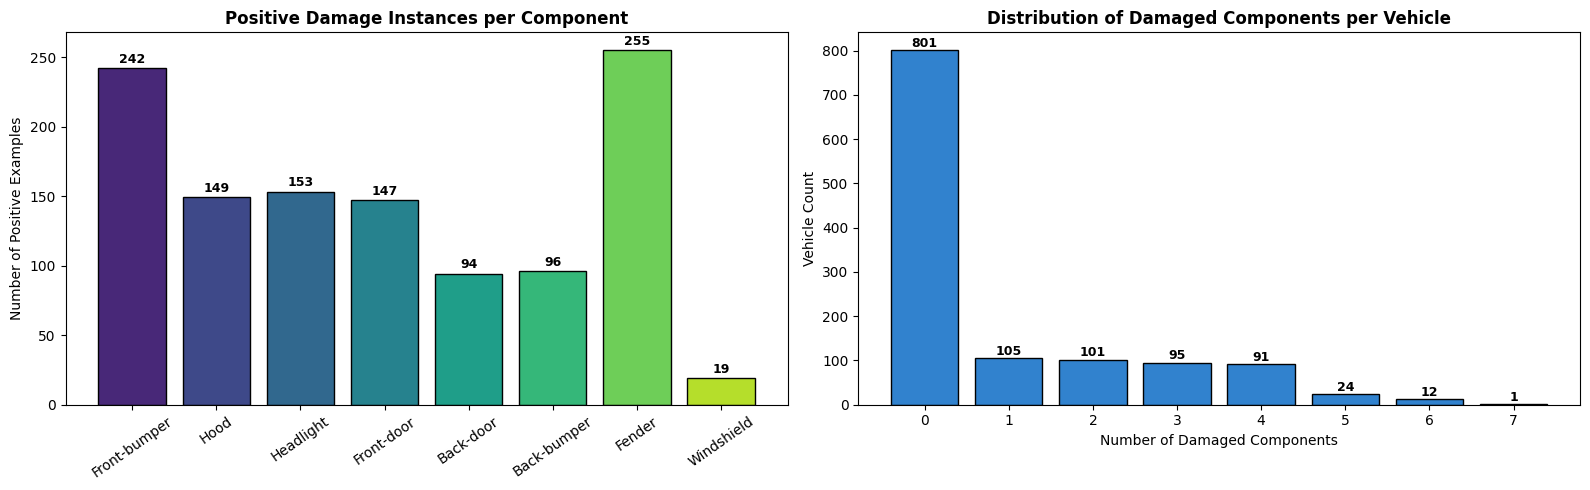

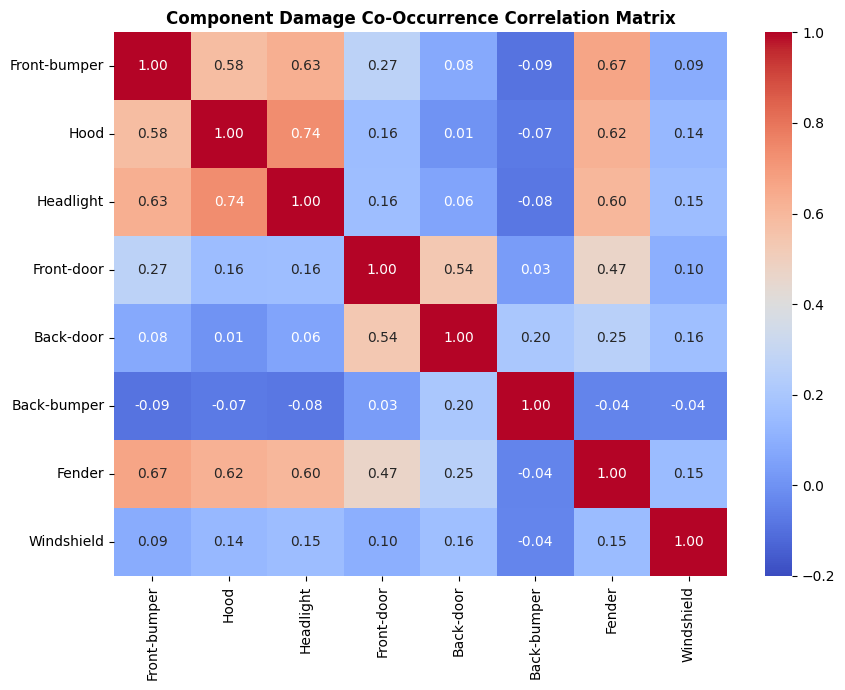

In [10]:
fig, axs = plt.subplots(1, 2, figsize=(16, 5))

# 1. Component Positive Counts
pos_counts = [df_clean[p].sum() for p in TARGET_PARTS]
colors = sns.color_palette("viridis", len(TARGET_PARTS))
bars = axs[0].bar(TARGET_PARTS, pos_counts, color=colors, edgecolor='black')
axs[0].set_title("Positive Damage Instances per Component", fontsize=12, fontweight='bold')
axs[0].set_ylabel("Number of Positive Examples")
axs[0].tick_params(axis='x', rotation=35)
for bar in bars:
    y = bar.get_height()
    axs[0].text(bar.get_x() + bar.get_width()/2, y + 4, f"{int(y)}", ha='center', fontweight='bold', fontsize=9)

# 2. Number of Damaged Components per Vehicle
damage_counts = df_clean['num_damaged_components'].value_counts().sort_index()
axs[1].bar(damage_counts.index, damage_counts.values, color='#3182ce', edgecolor='black')
axs[1].set_title("Distribution of Damaged Components per Vehicle", fontsize=12, fontweight='bold')
axs[1].set_xlabel("Number of Damaged Components")
axs[1].set_ylabel("Vehicle Count")
for idx, val in enumerate(damage_counts.values):
    axs[1].text(damage_counts.index[idx], val + 8, f"{val}", ha='center', fontweight='bold', fontsize=9)

plt.tight_layout()
plt.show()

# 3. Component Co-Occurrence Heatmap
plt.figure(figsize=(9, 7))
corr_matrix = df_clean[TARGET_PARTS].corr()
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', vmin=-0.2, vmax=1.0, cbar=True)
plt.title("Component Damage Co-Occurrence Correlation Matrix", fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()


## 8. Image Preprocessing & High-Performance tf.data Pipeline
Standardize all images into 3 RGB channels, resize to $224 \times 224$, and normalize to $[0.0, 1.0]$.


In [11]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 16
AUTOTUNE = tf.data.AUTOTUNE

def load_and_preprocess(img_path, label):
    raw = tf.io.read_file(img_path)
    img = tf.io.decode_image(raw, channels=3, expand_animations=False)
    img = tf.image.resize(img, IMG_SIZE, method='bilinear')
    img = tf.cast(img, tf.float32) / 255.0  # Normalize to [0.0, 1.0]
    return img, tf.cast(label, tf.float32)


## 9. Train, Validation and Test Partitioning (70% / 15% / 15%)
Perform stratified partitioning across multi-label targets to prevent distribution shifts. The test holdout is strictly isolated.


In [12]:
# Build target matrix
Y = df_clean[TARGET_PARTS].values
X = df_clean['image_path'].values

# Stratified split using is_damaged and num_damaged_components as strata proxy
strata = df_clean['is_damaged'].astype(str) + "_" + (df_clean['num_damaged_components'] > 0).astype(str)
train_idx, test_idx = train_test_split(np.arange(len(df_clean)), test_size=0.15, random_state=SEED, stratify=strata)
strata_train = strata.iloc[train_idx]
train_idx, val_idx = train_test_split(train_idx, test_size=(0.15/0.85), random_state=SEED, stratify=strata_train)

train_df = df_clean.iloc[train_idx].reset_index(drop=True)
val_df = df_clean.iloc[val_idx].reset_index(drop=True)
test_df = df_clean.iloc[test_idx].reset_index(drop=True)

print(f"Dataset Partitions:")
print(f"  - Train Set:      {len(train_df)} images ({len(train_df)/len(df_clean)*100:.1f}%)")
print(f"  - Validation Set: {len(val_df)} images ({len(val_df)/len(df_clean)*100:.1f}%)")
print(f"  - Test Set:       {len(test_df)} images ({len(test_df)/len(df_clean)*100:.1f}%)")

def build_dataset(df, is_train=False):
    x_paths = df['image_path'].values
    y_labels = df[TARGET_PARTS].values
    ds = tf.data.Dataset.from_tensor_slices((x_paths, y_labels))
    ds = ds.map(load_and_preprocess, num_parallel_calls=AUTOTUNE)
    if is_train:
        ds = ds.shuffle(buffer_size=512, seed=SEED, reshuffle_each_iteration=True)
        ds = ds.batch(BATCH_SIZE)
    else:
        ds = ds.batch(BATCH_SIZE)
    return ds.prefetch(AUTOTUNE)

train_ds = build_dataset(train_df, is_train=True)
val_ds = build_dataset(val_df, is_train=False)
test_ds = build_dataset(test_df, is_train=False)


Dataset Partitions:
  - Train Set:      860 images (69.9%)
  - Validation Set: 185 images (15.0%)
  - Test Set:       185 images (15.0%)


## 10. Data Augmentation
Apply domain-safe augmentations on training data only (horizontal flip, small rotation, zoom, contrast).


In [13]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal", seed=SEED),
    layers.RandomRotation(0.04, seed=SEED),
    layers.RandomZoom(0.08, seed=SEED),
    layers.RandomContrast(0.1, seed=SEED),
], name="data_augmentation")

# Calculate Class Weights to handle positive/negative imbalance
pos_counts = train_df[TARGET_PARTS].sum().values
neg_counts = len(train_df) - pos_counts
pos_weights = (neg_counts / (pos_counts + 1e-5)).astype(np.float32)
print("Computed Positive Loss Weights per Component:")
for i, p in enumerate(TARGET_PARTS):
    print(f"  {p:<15}: weight = {pos_weights[i]:.2f}")

def weighted_binary_crossentropy(y_true, y_pred):
    weights = tf.constant(pos_weights, dtype=tf.float32)
    bce = y_true * -tf.math.log(y_pred + 1e-7) * weights + (1.0 - y_true) * -tf.math.log(1.0 - y_pred + 1e-7)
    return tf.reduce_mean(bce)


Computed Positive Loss Weights per Component:
  Front-bumper   : weight = 3.97
  Hood           : weight = 7.04
  Headlight      : weight = 6.29
  Front-door     : weight = 7.96
  Back-door      : weight = 13.58
  Back-bumper    : weight = 11.11
  Fender         : weight = 3.89
  Windshield     : weight = 60.43


## 11. Model A: MobileNetV3Large (Two-Phase Transfer Learning)
Stage 1: Frozen backbone (learning rate $\eta = 10^{-3}$).  
Stage 2: Fine-tuning top 20 layers (learning rate $\eta = 10^{-5}$).


In [15]:
def build_mobilenet_model():
    inputs = layers.Input(shape=(224, 224, 3))
    x = data_augmentation(inputs)
    # MobileNet expects [-1, 1] scaling
    x = (x * 2.0) - 1.0
    base = tf.keras.applications.MobileNetV3Large(
        include_top=False, weights='imagenet', input_shape=(224, 224, 3)
    )
    base.trainable = False
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation='relu', kernel_regularizer=regularizers.l2(1e-4))(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(NUM_PARTS, activation='sigmoid', name="part_predictions")(x)
    return models.Model(inputs, outputs, name="MobileNetV3Large_MultiLabel"), base

model_mobilenet, base_mobilenet = build_mobilenet_model()

# Phase 1
model_mobilenet.compile(optimizer=optimizers.Adam(1e-3), loss=weighted_binary_crossentropy, metrics=['binary_accuracy'])
cb_phase1 = [
    EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-6)
]
print("--- Phase 1: Training Classification Head ---")
hist_mb_p1 = model_mobilenet.fit(train_ds, validation_data=val_ds, epochs=10, callbacks=cb_phase1, verbose=1)

# Phase 2: Fine-Tuning Top 20 Layers
base_mobilenet.trainable = True
for layer in base_mobilenet.layers[:-20]:
    layer.trainable = False

model_mobilenet.compile(optimizer=optimizers.Adam(1e-5), loss=weighted_binary_crossentropy, metrics=['binary_accuracy'])
cb_phase2 = [
    EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-7),
    ModelCheckpoint(os.path.join(ARTIFACTS_DIR, "best_mobilenetv3.keras"), monitor='val_loss', save_best_only=True)
]
print("--- Phase 2: Fine-Tuning Top 20 Layers ---")
hist_mb_p2 = model_mobilenet.fit(train_ds, validation_data=val_ds, epochs=10, callbacks=cb_phase2, verbose=1)


--- Phase 1: Training Classification Head ---
Epoch 1/10


C:\Users\aranj\anaconda3\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


54/54 ━━━━━━━━━━━━━━━━━━━━ 15s 183ms/step - binary_accuracy: 0.5872 - loss: 1.1838 - val_binary_accuracy: 0.6939 - val_loss: 1.1462 - learning_rate: 0.0010
Epoch 2/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 9s 142ms/step - binary_accuracy: 0.6090 - loss: 1.0602 - val_binary_accuracy: 0.7203 - val_loss: 1.1425 - learning_rate: 0.0010
Epoch 3/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 9s 144ms/step - binary_accuracy: 0.6164 - loss: 1.0370 - val_binary_accuracy: 0.6926 - val_loss: 1.0516 - learning_rate: 0.0010
Epoch 4/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 9s 142ms/step - binary_accuracy: 0.6461 - loss: 0.9883 - val_binary_accuracy: 0.6953 - val_loss: 0.9881 - learning_rate: 0.0010
Epoch 5/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 9s 141ms/step - binary_accuracy: 0.6488 - loss: 0.9778 - val_binary_accuracy: 0.6892 - val_loss: 0.9737 - learning_rate: 0.0010
Epoch 6/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 9s 142ms/step - binary_accuracy: 0.6510 - loss: 0.9516 - val_binary_accuracy: 0.6959 - val_loss: 0.9791 - learning_rate: 0.0010
Epoch 7/10
54/

## 12. Model B: EfficientNetB0 (Benchmark Model)
Two-phase transfer learning on EfficientNetB0 using compound scaling.


In [17]:
def build_efficientnet_model():
    inputs = layers.Input(shape=(224, 224, 3))
    x = data_augmentation(inputs)
    # EfficientNet expects [0, 255] inputs
    x = x * 255.0
    base = tf.keras.applications.EfficientNetB0(
        include_top=False, weights='imagenet', input_shape=(224, 224, 3)
    )
    base.trainable = False
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation='relu', kernel_regularizer=regularizers.l2(1e-4))(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(NUM_PARTS, activation='sigmoid', name="part_predictions")(x)
    return models.Model(inputs, outputs, name="EfficientNetB0_MultiLabel"), base

model_effnet, base_effnet = build_efficientnet_model()

# Phase 1
model_effnet.compile(optimizer=optimizers.Adam(1e-3), loss=weighted_binary_crossentropy, metrics=['binary_accuracy'])
print("--- EfficientNetB0 Phase 1 ---")
hist_eff_p1 = model_effnet.fit(train_ds, validation_data=val_ds, epochs=10, callbacks=cb_phase1, verbose=1)

# Phase 2
base_effnet.trainable = True
for layer in base_effnet.layers[:-25]:
    layer.trainable = False

model_effnet.compile(optimizer=optimizers.Adam(1e-5), loss=weighted_binary_crossentropy, metrics=['binary_accuracy'])
cb_eff_p2 = [
    EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-7),
    ModelCheckpoint(os.path.join(ARTIFACTS_DIR, "best_efficientnetb0.keras"), monitor='val_loss', save_best_only=True)
]
print("--- EfficientNetB0 Phase 2 ---")
hist_eff_p2 = model_effnet.fit(train_ds, validation_data=val_ds, epochs=10, callbacks=cb_eff_p2, verbose=1)


16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step
--- EfficientNetB0 Phase 1 ---
Epoch 1/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 22s 265ms/step - binary_accuracy: 0.6814 - loss: 1.0768 - val_binary_accuracy: 0.8074 - val_loss: 0.8787 - learning_rate: 0.0010
Epoch 2/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 13s 233ms/step - binary_accuracy: 0.7908 - loss: 0.7753 - val_binary_accuracy: 0.8169 - val_loss: 0.7899 - learning_rate: 0.0010
Epoch 3/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 14s 235ms/step - binary_accuracy: 0.8170 - loss: 0.6509 - val_binary_accuracy: 0.7905 - val_loss: 0.7265 - learning_rate: 0.0010
Epoch 4/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 21s 235ms/step - binary_accuracy: 0.8349 - loss: 0.5802 - val_binary_accuracy: 0.8574 - val_loss: 0.7936 - learning_rate: 0.0010
Epoch 5/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 14s 234ms/step - binary_accuracy: 0.8499 - loss: 0.5278 - val_binary_accuracy: 0.8716 - val_loss: 0.7758 - learning_rate: 0.0010
Epoch 6/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 13s 231ms/step - binary_accuracy: 0.8545 - lo

## 13. Model C: ResNet50 (Benchmark Model)
Two-phase transfer learning on deep residual architecture ResNet50.


In [19]:
def build_resnet_model():
    inputs = layers.Input(shape=(224, 224, 3))
    x = data_augmentation(inputs)
    # ResNet50 expects caffe-style BGR mean subtraction
    x = tf.keras.applications.resnet50.preprocess_input(x * 255.0)
    base = tf.keras.applications.ResNet50(
        include_top=False, weights='imagenet', input_shape=(224, 224, 3)
    )
    base.trainable = False
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation='relu', kernel_regularizer=regularizers.l2(1e-4))(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(NUM_PARTS, activation='sigmoid', name="part_predictions")(x)
    return models.Model(inputs, outputs, name="ResNet50_MultiLabel"), base

model_resnet, base_resnet = build_resnet_model()

# Phase 1
model_resnet.compile(optimizer=optimizers.Adam(1e-3), loss=weighted_binary_crossentropy, metrics=['binary_accuracy'])
print("--- ResNet50 Phase 1 ---")
hist_res_p1 = model_resnet.fit(train_ds, validation_data=val_ds, epochs=10, callbacks=cb_phase1, verbose=1)

# Phase 2
base_resnet.trainable = True
for layer in base_resnet.layers[:-20]:
    layer.trainable = False

model_resnet.compile(optimizer=optimizers.Adam(1e-5), loss=weighted_binary_crossentropy, metrics=['binary_accuracy'])
cb_res_p2 = [
    EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-7),
    ModelCheckpoint(os.path.join(ARTIFACTS_DIR, "best_resnet50.keras"), monitor='val_loss', save_best_only=True)
]
print("--- ResNet50 Phase 2 ---")
hist_res_p2 = model_resnet.fit(train_ds, validation_data=val_ds, epochs=10, callbacks=cb_res_p2, verbose=1)


94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 15s 0us/step
--- ResNet50 Phase 1 ---
Epoch 1/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 37s 594ms/step - binary_accuracy: 0.6818 - loss: 1.1456 - val_binary_accuracy: 0.7757 - val_loss: 0.8589 - learning_rate: 0.0010
Epoch 2/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 29s 525ms/step - binary_accuracy: 0.7766 - loss: 0.8087 - val_binary_accuracy: 0.8446 - val_loss: 0.8331 - learning_rate: 0.0010
Epoch 3/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 29s 521ms/step - binary_accuracy: 0.7833 - loss: 0.7133 - val_binary_accuracy: 0.8480 - val_loss: 0.8451 - learning_rate: 0.0010
Epoch 4/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 29s 526ms/step - binary_accuracy: 0.8029 - loss: 0.6723 - val_binary_accuracy: 0.8649 - val_loss: 0.8280 - learning_rate: 0.0010
Epoch 5/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 32s 570ms/step - binary_accuracy: 0.8352 - loss: 0.5698 - val_binary_accuracy: 0.8554 - val_loss: 0.7918 - learning_rate: 0.0010
Epoch 6/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 41s 563ms/step - binary_accuracy: 0.8485 - loss: 0

## 14 & 15. Comprehensive Multi-Label Evaluation & Threshold Optimization
We optimize classification decision thresholds per component on the validation set to maximize F1-score.
We evaluate:
- **Binary Accuracy** vs **Exact Match Ratio** (Subset Accuracy)
- **Hamming Loss** (Fraction of wrong labels)
- **Macro F1**, **Micro F1**, and **PR-AUC**


In [21]:
def evaluate_multilabel_model(model, ds, name="Model", thresholds=None):
    y_true_list = []
    y_prob_list = []
    for imgs, labels in ds:
        probs = model.predict(imgs, verbose=0)
        y_true_list.append(labels.numpy())
        y_prob_list.append(probs)
        
    y_true = np.vstack(y_true_list)
    y_prob = np.vstack(y_prob_list)
    
    # If thresholds not provided, optimize on validation data
    if thresholds is None:
        thresholds = []
        for col in range(NUM_PARTS):
            ths = np.linspace(0.1, 0.9, 81)
            best_f1, best_th = 0.0, 0.5
            for th in ths:
                pred_c = (y_prob[:, col] >= th).astype(int)
                f1_c = f1_score(y_true[:, col], pred_c, zero_division=0)
                if f1_c > best_f1:
                    best_f1 = f1_c
                    best_th = th
            thresholds.append(best_th)
        thresholds = np.array(thresholds)
        
    y_pred = (y_prob >= thresholds).astype(int)
    
    # Multi-label metrics
    bin_acc = np.mean(y_true == y_pred)
    exact_acc = accuracy_score(y_true, y_pred)
    h_loss = hamming_loss(y_true, y_pred)
    macro_f1 = f1_score(y_true, y_pred, average='macro', zero_division=0)
    micro_f1 = f1_score(y_true, y_pred, average='micro', zero_division=0)
    precision_macro = precision_score(y_true, y_pred, average='macro', zero_division=0)
    recall_macro = recall_score(y_true, y_pred, average='macro', zero_division=0)
    
    # PR-AUC
    pr_aucs = []
    for col in range(NUM_PARTS):
        p, r, _ = precision_recall_curve(y_true[:, col], y_prob[:, col])
        pr_aucs.append(auc(r, p))
    mean_pr_auc = np.mean(pr_aucs)
    
    return {
        'model_name': name,
        'binary_accuracy': bin_acc,
        'exact_match_ratio': exact_acc,
        'hamming_loss': h_loss,
        'precision_macro': precision_macro,
        'recall_macro': recall_macro,
        'macro_f1': macro_f1,
        'micro_f1': micro_f1,
        'mean_pr_auc': mean_pr_auc,
        'thresholds': thresholds,
        'y_true': y_true,
        'y_pred': y_pred,
        'y_prob': y_prob
    }

# Calibrate optimal thresholds on Validation Set
print("Calibrating Component Decision Thresholds on Validation Set...")
val_eval_mb = evaluate_multilabel_model(model_mobilenet, val_ds, "MobileNetV3Large")
val_eval_eff = evaluate_multilabel_model(model_effnet, val_ds, "EfficientNetB0")
val_eval_res = evaluate_multilabel_model(model_resnet, val_ds, "ResNet50")

print("Optimal Component Thresholds (MobileNetV3):")
for i, p in enumerate(TARGET_PARTS):
    print(f"  {p:<15}: threshold = {val_eval_mb['thresholds'][i]:.2f}")


Calibrating Component Decision Thresholds on Validation Set...
Optimal Component Thresholds (MobileNetV3):
  Front-bumper   : threshold = 0.48
  Hood           : threshold = 0.56
  Headlight      : threshold = 0.40
  Front-door     : threshold = 0.61
  Back-door      : threshold = 0.62
  Back-bumper    : threshold = 0.46
  Fender         : threshold = 0.59
  Windshield     : threshold = 0.30


## 16. Architecture Comparison Matrix
Compare MobileNetV3Large, EfficientNetB0, and ResNet50 on validation metrics.


In [22]:
comparison_data = [
    {
        'Model': val_eval_mb['model_name'],
        'Binary Accuracy': f"{val_eval_mb['binary_accuracy']*100:.2f}%",
        'Exact Match Ratio': f"{val_eval_mb['exact_match_ratio']*100:.2f}%",
        'Hamming Loss': f"{val_eval_mb['hamming_loss']:.4f}",
        'Precision (Macro)': f"{val_eval_mb['precision_macro']:.4f}",
        'Recall (Macro)': f"{val_eval_mb['recall_macro']:.4f}",
        'Macro F1': f"{val_eval_mb['macro_f1']:.4f}",
        'Micro F1': f"{val_eval_mb['micro_f1']:.4f}",
        'Mean PR-AUC': f"{val_eval_mb['mean_pr_auc']:.4f}"
    },
    {
        'Model': val_eval_eff['model_name'],
        'Binary Accuracy': f"{val_eval_eff['binary_accuracy']*100:.2f}%",
        'Exact Match Ratio': f"{val_eval_eff['exact_match_ratio']*100:.2f}%",
        'Hamming Loss': f"{val_eval_eff['hamming_loss']:.4f}",
        'Precision (Macro)': f"{val_eval_eff['precision_macro']:.4f}",
        'Recall (Macro)': f"{val_eval_eff['recall_macro']:.4f}",
        'Macro F1': f"{val_eval_eff['macro_f1']:.4f}",
        'Micro F1': f"{val_eval_eff['micro_f1']:.4f}",
        'Mean PR-AUC': f"{val_eval_eff['mean_pr_auc']:.4f}"
    },
    {
        'Model': val_eval_res['model_name'],
        'Binary Accuracy': f"{val_eval_res['binary_accuracy']*100:.2f}%",
        'Exact Match Ratio': f"{val_eval_res['exact_match_ratio']*100:.2f}%",
        'Hamming Loss': f"{val_eval_res['hamming_loss']:.4f}",
        'Precision (Macro)': f"{val_eval_res['precision_macro']:.4f}",
        'Recall (Macro)': f"{val_eval_res['recall_macro']:.4f}",
        'Macro F1': f"{val_eval_res['macro_f1']:.4f}",
        'Micro F1': f"{val_eval_res['micro_f1']:.4f}",
        'Mean PR-AUC': f"{val_eval_res['mean_pr_auc']:.4f}"
    }
]

df_comp = pd.DataFrame(comparison_data)
display(df_comp)


,Model,Binary Accuracy,Exact Match Ratio,Hamming Loss,Precision (Macro),Recall (Macro),Macro F1,Micro F1,Mean PR-AUC
0,MobileNetV3Large,75.27%,48.65%,0.2473,0.3096,0.7590,0.4060,0.4135,0.3358
1,EfficientNetB0,89.73%,65.95%,0.1027,0.5140,0.6622,0.5670,0.6200,0.4504
2,ResNet50,90.20%,66.49%,0.0980,0.5327,0.6707,0.5876,0.6420,0.4917


## 17. Final Model Selection & Isolated Test Evaluation
Evaluate the winning architecture **exactly once** on the independent test set using the thresholds calibrated on validation data.


In [23]:
# Select model with highest validation Macro F1
models_map = {
    'MobileNetV3Large': (model_mobilenet, val_eval_mb['thresholds']),
    'EfficientNetB0': (model_effnet, val_eval_eff['thresholds']),
    'ResNet50': (model_resnet, val_eval_res['thresholds'])
}

best_name = max(['MobileNetV3Large', 'EfficientNetB0', 'ResNet50'], 
                key=lambda k: [m for m in comparison_data if m['Model'] == k][0]['Macro F1'])
best_model, best_thresholds = models_map[best_name]

print(f"Selected Best Architecture: {best_name}")
print("=" * 70)
print("FINAL UNSEEN TEST EVALUATION REPORT")
print("=" * 70)

test_eval = evaluate_multilabel_model(best_model, test_ds, best_name, thresholds=best_thresholds)

print(f"Test Binary Accuracy:     {test_eval['binary_accuracy']*100:.2f}%")
print(f"Test Exact Match Ratio:   {test_eval['exact_match_ratio']*100:.2f}%")
print(f"Test Hamming Loss:        {test_eval['hamming_loss']:.4f}")
print(f"Test Macro F1:            {test_eval['macro_f1']:.4f}")
print(f"Test Micro F1:            {test_eval['micro_f1']:.4f}")
print(f"Test Mean PR-AUC:         {test_eval['mean_pr_auc']:.4f}")

print("\nPer-Component Detailed Performance on Test Set:")
print(classification_report(test_eval['y_true'], test_eval['y_pred'], target_names=TARGET_PARTS, digits=4))


Selected Best Architecture: ResNet50
FINAL UNSEEN TEST EVALUATION REPORT
Test Binary Accuracy:     88.99%
Test Exact Match Ratio:   68.65%
Test Hamming Loss:        0.1101
Test Macro F1:            0.4879
Test Micro F1:            0.5995
Test Mean PR-AUC:         0.4685

Per-Component Detailed Performance on Test Set:
              precision    recall  f1-score   support

Front-bumper     0.6170    0.9062    0.7342        32
        Hood     0.3871    0.6000    0.4706        20
   Headlight     0.3333    0.8667    0.4815        15
  Front-door     0.4054    0.6522    0.5000        23
   Back-door     0.4500    0.5294    0.4865        17
 Back-bumper     0.6250    0.3333    0.4348        15
      Fender     0.6964    0.9286    0.7959        42
  Windshield     0.0000    0.0000    0.0000         1

   micro avg     0.5041    0.7394    0.5995       165
   macro avg     0.4393    0.6021    0.4879       165
weighted avg     0.5339    0.7394    0.6051       165
 samples avg     0.1745    0.2

C:\Users\aranj\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in samples with no predicted labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\aranj\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in samples with no true labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\aranj\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in samples with no true nor predicted labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


## 18. Reusable Prediction Function
Accepts any vehicle photograph and predicts the damage status across all eight components.


       AI VEHICLE INSURANCE CLAIM INSPECTION REPORT
Vehicle Photograph:   Car damages 1076.png
Overall Status:       Damaged
Damaged Parts Count:  5 component(s)
-----------------------------------------------------------------
Component-Level Prediction Scores:
  [X] Front-bumper   : Damaged    | Score: 89.5%   (Threshold: 42.0%)
  [X] Hood           : Damaged    | Score: 94.0%   (Threshold: 60.0%)
  [X] Headlight      : Damaged    | Score: 92.6%   (Threshold: 31.0%)
  [X] Front-door     : Damaged    | Score: 72.7%   (Threshold: 63.0%)
  [ ] Back-door      : Undamaged  | Score: 40.1%   (Threshold: 74.0%)
  [ ] Back-bumper    : Undamaged  | Score: 49.2%   (Threshold: 86.0%)
  [X] Fender         : Damaged    | Score: 93.2%   (Threshold: 28.0%)
  [ ] Windshield     : Undamaged  | Score: 65.1%   (Threshold: 83.0%)


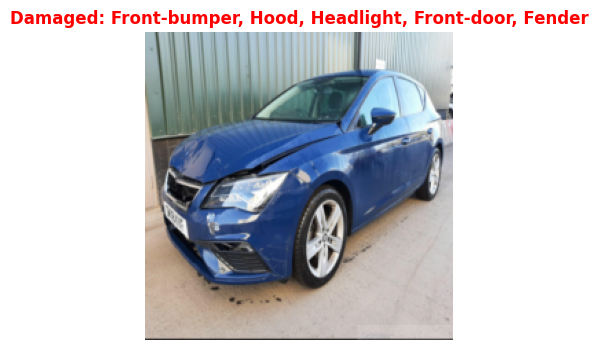

In [24]:
def predict_vehicle_damage(image_path, model=best_model, thresholds=best_thresholds):
    """
    Autonomous inference function returning component-level damage predictions.
    """
    img_pil = Image.open(image_path).convert('RGB')
    resized = img_pil.resize(IMG_SIZE, Image.Resampling.BILINEAR)
    arr = np.expand_dims(np.array(resized, dtype=np.float32) / 255.0, axis=0)
    
    probs = model.predict(arr, verbose=0)[0]
    
    detected = []
    component_report = {}
    for i, part in enumerate(TARGET_PARTS):
        p_score = float(probs[i]) * 100
        th = float(thresholds[i]) * 100
        is_hit = p_score >= th
        status = "Damaged" if is_hit else "Undamaged"
        if is_hit:
            detected.append(part)
        component_report[part] = {
            'status': status,
            'prediction_score': f"{p_score:.1f}%",
            'threshold': f"{th:.1f}%"
        }
        
    overall_status = "Damaged" if len(detected) > 0 else "Undamaged"
    
    print("=" * 65)
    print("       AI VEHICLE INSURANCE CLAIM INSPECTION REPORT")
    print("=" * 65)
    print(f"Vehicle Photograph:   {os.path.basename(image_path)}")
    print(f"Overall Status:       {overall_status}")
    print(f"Damaged Parts Count:  {len(detected)} component(s)")
    print("-" * 65)
    print("Component-Level Prediction Scores:")
    for part in TARGET_PARTS:
        info = component_report[part]
        mark = "[X]" if info['status'] == "Damaged" else "[ ]"
        print(f"  {mark} {part:<15}: {info['status']:<10} | Score: {info['prediction_score']:<7} (Threshold: {info['threshold']})")
    print("=" * 65)
    
    # Visual Output
    plt.figure(figsize=(6, 4))
    plt.imshow(resized)
    color = 'red' if overall_status == "Damaged" else 'green'
    plt.title(f"{overall_status}: {', '.join(detected) if detected else 'Intact'}", color=color, fontweight='bold')
    plt.axis('off')
    plt.show()
    
    return component_report

# Test on a sample vehicle
sample_test_path = test_df.iloc[0]['image_path']
result = predict_vehicle_damage(sample_test_path)


## 19. Save and Export Artifacts
Export model architecture, weights, optimal thresholds, preprocessing metadata, and evaluation reports.


In [25]:
# 1. Save Best Model
best_model_path = os.path.join(ARTIFACTS_DIR, "best_multilabel_model.keras")
best_model.save(best_model_path)
print(f"Model saved to: {best_model_path}")

# 2. Save Configuration and Optimal Thresholds
config = {
    'model_architecture': best_name,
    'target_components': TARGET_PARTS,
    'optimal_thresholds': {TARGET_PARTS[i]: float(best_thresholds[i]) for i in range(NUM_PARTS)},
    'input_size': [224, 224, 3],
    'normalization': 'pixel / 255.0',
    'test_metrics': {
        'binary_accuracy': float(test_eval['binary_accuracy']),
        'exact_match_ratio': float(test_eval['exact_match_ratio']),
        'macro_f1': float(test_eval['macro_f1']),
        'micro_f1': float(test_eval['micro_f1']),
        'mean_pr_auc': float(test_eval['mean_pr_auc'])
    }
}
config_path = os.path.join(ARTIFACTS_DIR, "multilabel_config.json")
with open(config_path, 'w') as f:
    json.dump(config, f, indent=4)
print(f"Configuration metadata saved to: {config_path}")


Model saved to: D:\MLP course files\Deep learning\Resume project\model_artifacts\best_multilabel_model.keras
Configuration metadata saved to: D:\MLP course files\Deep learning\Resume project\model_artifacts\multilabel_config.json
